Rows and columns: (19999, 15)
<class 'pandas.DataFrame'>
RangeIndex: 19999 entries, 0 to 19998
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   19999 non-null  int64  
 1   id           19999 non-null  int64  
 2   price        19999 non-null  int64  
 3   bedrooms     19986 non-null  float64
 4   bathrooms    19989 non-null  float64
 5   sqft_living  19999 non-null  int64  
 6   sqft_total   19999 non-null  int64  
 7   floors       19999 non-null  float64
 8   waterfront   19999 non-null  int64  
 9   view         19999 non-null  int64  
 10  condition    19999 non-null  int64  
 11  grade        19999 non-null  int64  
 12  built        19999 non-null  int64  
 13  renovated    19999 non-null  int64  
 14  living_area  19999 non-null  int64  
dtypes: float64(3), int64(12)
memory usage: 2.3 MB
waterfront
waterfront
No     19840
Yes      159
Name: count, dtype: int64

view
view
0    17973
1      317


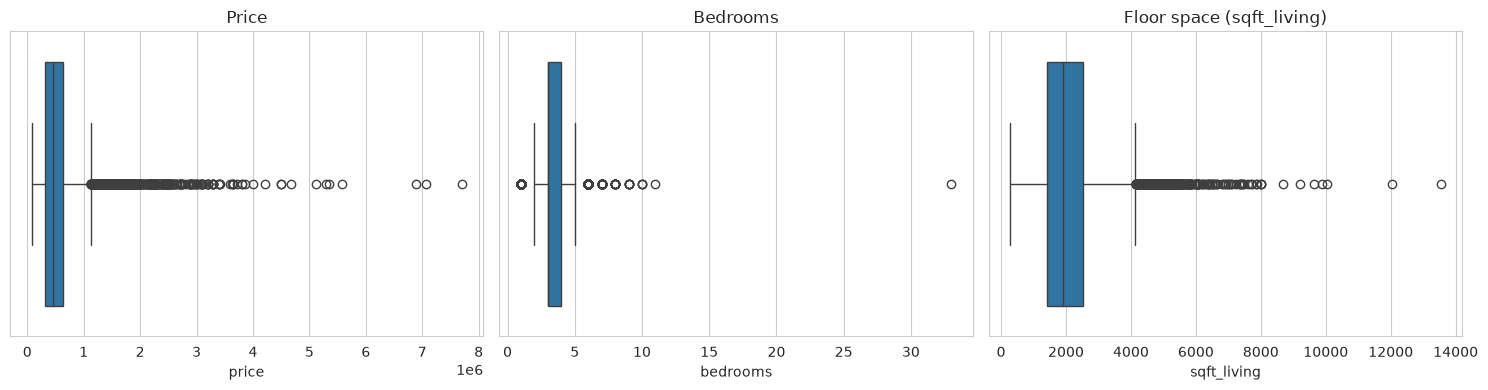

Duplicates removed: 2
Rows with missing values: 16
               id   price  bedrooms  bathrooms  sqft_living
15870  2402100895  640000        33       1.75         1620
Rows where sqft_living > sqft_total: 452
floors
2.0    227
3.0    195
2.5     16
1.5      6
1.0      4
3.5      4
Name: count, dtype: int64
Rows before: 19999  Rows after: 19980  Removed: 19
Missing values left: 0
Duplicate rows left: 0
Skew of price: 4.12  Skew of log_price: 0.42


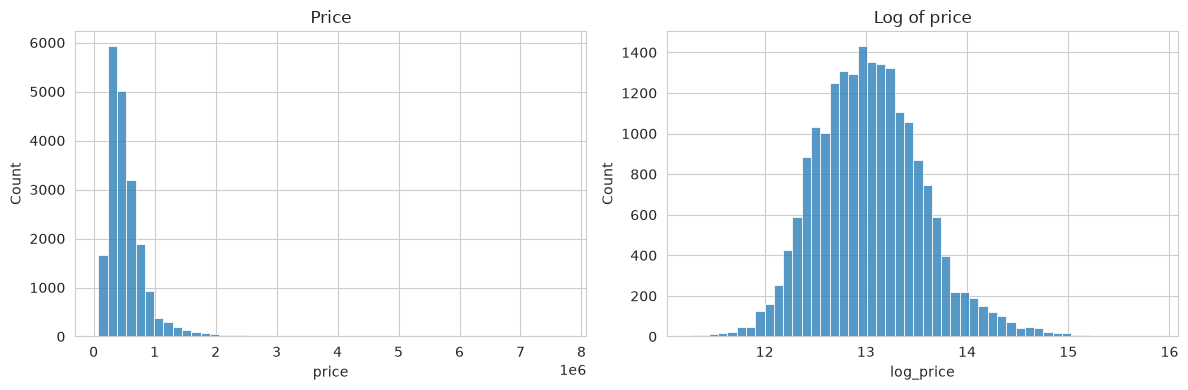

waterfront
No     19821
Yes      159
Name: count, dtype: int64

waterfront
No     99.2
Yes     0.8
Name: proportion, dtype: float64


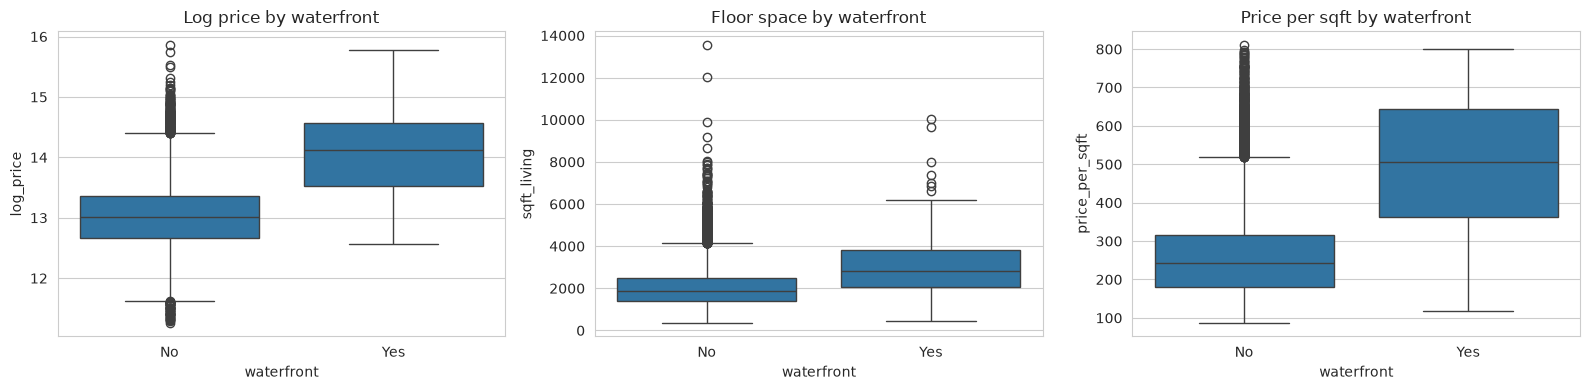

price  U = 2783052.5  p = 2.3153891776635906e-62
sqft_living  U = 2313908.0  p = 2.20426217775981e-24
price_per_sqft  U = 2776239.0  p = 1.1130148353422016e-61
       sqft_living  living_area  sqft_total
count      19980.0      19980.0     19980.0
mean        2058.0       1974.0     15601.0
std          905.0        675.0     41766.0
min          370.0        399.0       520.0
25%         1420.0       1490.0      5350.0
50%         1900.0       1830.0      7819.0
75%         2510.0       2337.0     11000.0
max        13540.0       6210.0   1651359.0


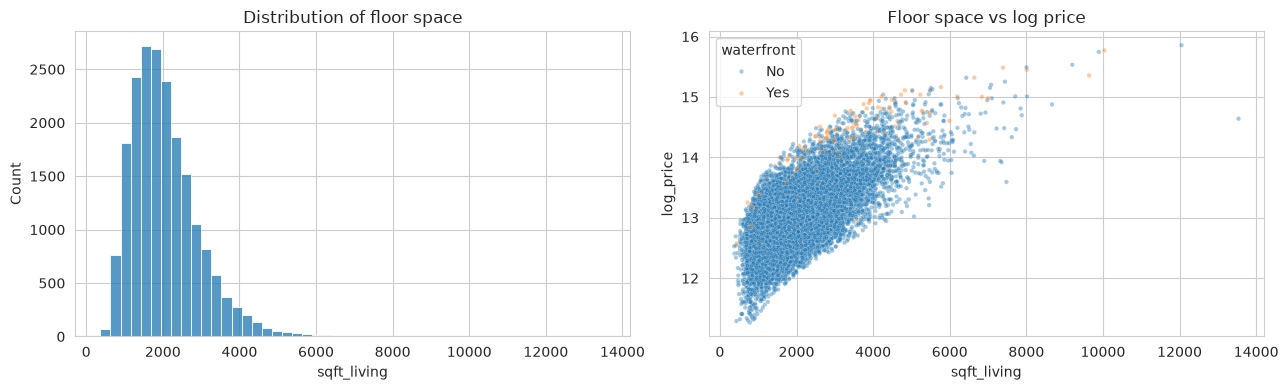

sqft_living  Pearson r = 0.701  Spearman rho = 0.642  p = 0.0
living_area  Pearson r = 0.596  Spearman rho = 0.579  p = 0.0
sqft_total  Pearson r = 0.086  Spearman rho = 0.073  p = 3.2601329502849156e-25
count    19980.000000
mean      1967.947297
std         28.317778
min       1900.000000
25%       1950.000000
50%       1969.000000
75%       1991.000000
max       2015.000000
Name: built, dtype: float64
Pearson r = 0.04  p = 1.1917396245794723e-08
Spearman rho = 0.082  p = 7.417012339335026e-31


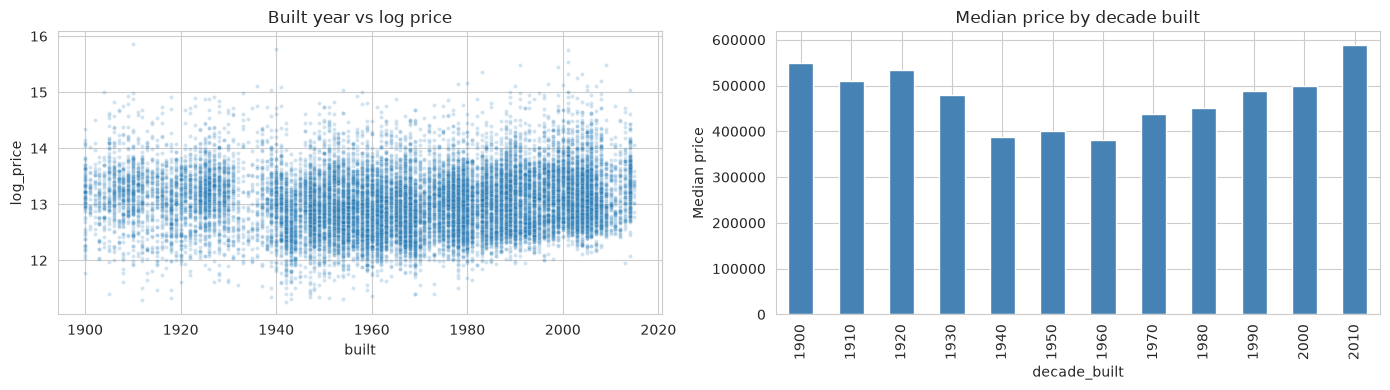

H = 1134.9  p = 1.7573972046756019e-236


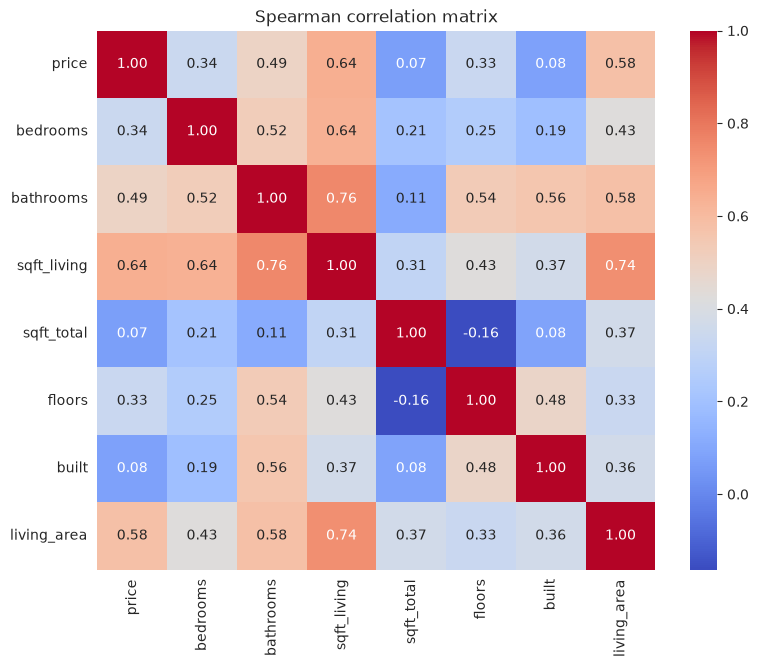

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

df = pd.read_csv("Manchester_house_Dataset[3678].csv")
print('Rows and columns:', df.shape)
df.head()
df.info()
df = df.drop(columns=['Unnamed: 0'])
df.columns
df['id'] = df['id'].astype(str)
df['bedrooms'] = df['bedrooms'].astype('Int64')
df['waterfront'] = df['waterfront'].map({0: 'No', 1: 'Yes'}).astype('category')
for col in ['view', 'condition', 'grade']:
    df[col] = pd.Categorical(df[col], ordered=True)
    df.dtypes
    df.describe().T
    for col in ['waterfront', 'view', 'condition', 'grade']:
        print(col)
        print(df[col].value_counts().sort_index())
        print()
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Exact duplicate rows:', df.duplicated().sum())
print('Repeated ids (repeat sales):', df['id'].duplicated().sum())
print('Highest bedroom counts:', sorted(df['bedrooms'].dropna().unique())[-5:])
num_cols = ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_total',
            'floors', 'built', 'living_area']
df[num_cols].skew().round(2)
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print('Upper fence:', upper)
print('Price outliers above fence:', (df['price'] > upper).sum())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=df['price'], ax=axes[0]).set_title('Price')
sns.boxplot(x=df['bedrooms'], ax=axes[1]).set_title('Bedrooms')
sns.boxplot(x=df['sqft_living'], ax=axes[2]).set_title('Floor space (sqft_living)')
plt.tight_layout()
plt.show()
before_stats = df[num_cols].describe().T
before_skew = df[num_cols].skew()
rows_before = len(df)
print('Duplicates removed:', df.duplicated().sum())
df = df.drop_duplicates()
print('Rows with missing values:', df[['bedrooms', 'bathrooms']].isnull().any(axis=1).sum())
df = df.dropna(subset=['bedrooms', 'bathrooms'])
print(df[df['bedrooms'] > 20][['id', 'price', 'bedrooms', 'bathrooms', 'sqft_living']])
df = df[df['bedrooms'] <= 20]
print('Rows where sqft_living > sqft_total:', (df['sqft_living'] > df['sqft_total']).sum())
print(df[df['sqft_living'] > df['sqft_total']]['floors'].value_counts())
df['renovated'] = np.where(df['renovated'] > 0, 'Yes', 'No')
df['renovated'] = df['renovated'].astype('category')
df['renovated'].value_counts()
df['log_price'] = np.log(df['price'])
df['price_per_sqft'] = df['price'] / df['sqft_living']
df['decade_built'] = (df['built'] // 10) * 10
df = df.reset_index(drop=True)
print('Rows before:', rows_before, ' Rows after:', len(df), ' Removed:', rows_before - len(df))
num_cols_after = ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_total',
                  'floors', 'built', 'living_area']
after_stats = df[num_cols_after].describe().T
df[num_cols_after + ['log_price']].describe().T
comparison = pd.DataFrame({
    'count_before': before_stats['count'],
    'count_after': after_stats['count'],
    'mean_before': before_stats['mean'].round(2),
    'mean_after': after_stats['mean'].round(2),
    'max_before': before_stats['max'],
    'max_after': after_stats['max'],
    'skew_before': before_skew.round(2),
    'skew_after': df[num_cols_after].skew().round(2)
})
comparison
print('Missing values left:', df.isnull().sum().sum())
print('Duplicate rows left:', df.duplicated().sum())
print('Skew of price:', round(df['price'].skew(), 2), ' Skew of log_price:', round(df['log_price'].skew(), 2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=50, ax=axes[0]).set_title('Price')
sns.histplot(df['log_price'], bins=50, ax=axes[1]).set_title('Log of price')
plt.tight_layout()
plt.show()
print(df['waterfront'].value_counts())
print()
print(df['waterfront'].value_counts(normalize=True).round(4) * 100)
df.groupby('waterfront', observed=True)[['price', 'sqft_living', 'price_per_sqft']].agg(['mean', 'median']).round(0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x='waterfront', y='log_price', ax=axes[0]).set_title('Log price by waterfront')
sns.boxplot(data=df, x='waterfront', y='sqft_living', ax=axes[1]).set_title('Floor space by waterfront')
sns.boxplot(data=df, x='waterfront', y='price_per_sqft', ax=axes[2]).set_title('Price per sqft by waterfront')
plt.tight_layout()
plt.show()
water = df[df['waterfront'] == 'Yes']
non_water = df[df['waterfront'] == 'No']

for col in ['price', 'sqft_living', 'price_per_sqft']:
    u, p = stats.mannwhitneyu(water[col], non_water[col], alternative='two-sided')
    print(col, ' U =', round(u, 1), ' p =', p)
pd.crosstab(df['view'], df['waterfront'])
print(df[['sqft_living', 'living_area', 'sqft_total']].describe().round(0))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['sqft_living'], bins=50, ax=axes[0]).set_title('Distribution of floor space')
sns.scatterplot(data=df, x='sqft_living', y='log_price', hue='waterfront',
                alpha=0.4, s=10, ax=axes[1]).set_title('Floor space vs log price')
plt.tight_layout()
plt.show()
for col in ['sqft_living', 'living_area', 'sqft_total']:
    r, p1 = stats.pearsonr(df[col], df['price'])
    rho, p2 = stats.spearmanr(df[col], df['price'])
    print(col, ' Pearson r =', round(r, 3), ' Spearman rho =', round(rho, 3), ' p =', p2)
df['size_band'] = pd.qcut(df['sqft_living'], 5)
df.groupby('size_band', observed=True)['price'].median()
print(df['built'].describe())
r, p1 = stats.pearsonr(df['built'], df['price'])
rho, p2 = stats.spearmanr(df['built'], df['price'])
print('Pearson r =', round(r, 3), ' p =', p1)
print('Spearman rho =', round(rho, 3), ' p =', p2)
decade_summary = df.groupby('decade_built')['price'].agg(['count', 'median']).round(0)
decade_summary
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(data=df, x='built', y='log_price', alpha=0.2, s=8, ax=axes[0]).set_title('Built year vs log price')
decade_summary['median'].plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Median price by decade built')
axes[1].set_ylabel('Median price')
plt.tight_layout()
plt.show()
groups = [group['price'] for name, group in df.groupby('decade_built')]
h, p = stats.kruskal(*groups)
print('H =', round(h, 1), ' p =', p)
df.groupby('decade_built')[['sqft_living', 'price_per_sqft']].median().round(0)
corr_cols = ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_total',
             'floors', 'built', 'living_area']
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].astype(float).corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Spearman correlation matrix')
plt.show()